# Part 1 — Segmentation by classification on the Leaf Disease Segmentation dataset

**Task:** binary segmentation, every pixel is either **diseased (1)** or **not diseased (0)**
(healthy leaf tissue *and* the image background are both class 0). The dataset is already binary, so no
class grouping is needed.

**Idea of Part 1:** train an ordinary classifier that looks at *one pixel* (1.1), or at a *small patch around
the pixel* (1.2, 1.3), and predicts the class of that pixel. Applying it to every pixel of a test image gives a
segmentation mask.

| Section | Input to the classifier | Classifiers |
|---|---|---|
| 1.1 | RGB of the pixel (3 values) | logistic regression, kNN |
| 1.2a | raw 15×15 RGB patch (675 values) | logistic regression, random forest |
| 1.2b | hand-crafted patch features (mean/std RGB, gradient, saturation…) | LR, RF, SVM, MLP |
| 1.3 | raw patch | Keras MLP (flattened) and CNN (15×15×3) |

Before running: download the dataset and set `DATA_ROOT` in the configuration cell (section 0 explains the data).

In [3]:
%matplotlib inline
import time
from pathlib import Path
import numpy as np
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy import ndimage as ndi
from sklearn import metrics
import seaborn as sns


# Folder where you unzipped the Kaggle download. The first existing candidate is used.
_candidates = [Path("leaf_disease_segmentation"),              # next to this notebook
               Path("../leaf_disease_segmentation"),
               Path("../datasets/leaf_disease_segmentation")]
DATA_ROOT = next((p for p in _candidates if p.exists()), _candidates[0])
print("Using data from:", DATA_ROOT.resolve())
IMG_SIZE = 256         # every image and mask is resized to IMG_SIZE x IMG_SIZE
VAL_FRACTION = 0.15    # part of the official training images kept aside for validation
PATCH = 15             # patch size used in 1.2 / 1.3
N_PER_IMG = 50         # random pixels sampled per image (assignment example: 50)
N_SEG_EVAL = 20        # number of full test images used to compute mean IoU / Dice
SEED = 0
rng = np.random.default_rng(SEED)

Using data from: C:\Users\kevin\PycharmProjects\pythonProjectRiz24\project_leaf_disease_detection\leaf_disease_segmentation


## 0. The data: exploration and preparation

Dataset: [Leaf Disease Segmentation with train/valid split](https://www.kaggle.com/datasets/sovitrath/leaf-disease-segmentation-with-trainvalid-split).
Download it, unzip it **outside the repo** (it's git-ignored anyway) and set `DATA_ROOT` above.

### 0.1 What's in the folder?

In [4]:
from collections import Counter

def show_tree(root, max_depth=3):
    for d in sorted([root] + [p for p in root.rglob("*") if p.is_dir()]):
        depth = len(d.relative_to(root).parts)
        if depth <= max_depth:
            counts = Counter(f.suffix.lower() for f in d.iterdir() if f.is_file())
            print("    " * depth + f"{d.name}/   " + ", ".join(f"{n} {e}" for e, n in counts.most_common(3)))

assert DATA_ROOT.exists(), f"{DATA_ROOT.resolve()} not found - set DATA_ROOT in the first cell"
show_tree(DATA_ROOT)

leaf_disease_segmentation/   
    aug_data/   
        train_images/   2500 .jpg
        train_masks/   2500 .png
        valid_images/   440 .jpg
        valid_masks/   440 .png
    orig_data/   
        train_images/   498 .jpg
        train_masks/   498 .png
        valid_images/   90 .jpg
        valid_masks/   90 .png


There are two copies of the data. `aug_data` holds augmented versions of the same leaves; using it would
put near-duplicates of training images into validation, so we use **only `orig_data`**.

# TBD


In [5]:
ORIG = next(p for p in [DATA_ROOT / "orig_data", DATA_ROOT] if (p / "train_images").exists())
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def find_pairs(img_dir, mask_dir):
    """Match every image with the mask that has the same file name (any extension)."""
    masks = {p.stem: p for p in mask_dir.iterdir() if p.suffix.lower() in IMG_EXTS}
    imgs = sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXTS)
    pairs = [(p, masks[p.stem]) for p in imgs if p.stem in masks]
    missing = [p.name for p in imgs if p.stem not in masks]
    print(f"{img_dir.name}: {len(imgs)} images, {len(pairs)} with a mask"
          + (f", missing e.g. {missing[:3]}" if missing else ""))
    return pairs

train_pairs = find_pairs(ORIG / "train_images", ORIG / "train_masks")
test_pairs = find_pairs(ORIG / "valid_images", ORIG / "valid_masks")

train_images: 498 images, 498 with a mask
valid_images: 90 images, 90 with a mask


### 0.2 Image sizes
The images do not all have the same size, so we will resize them (and their masks) to `IMG_SIZE`.

# TBC CHECKED FOR ALT OF RESIZE OR    WILL STICK TO THIS

width  94-4160 px, height 150-3264 px
most common sizes: [((256, 256), 277), ((800, 600), 10), ((400, 300), 6)]


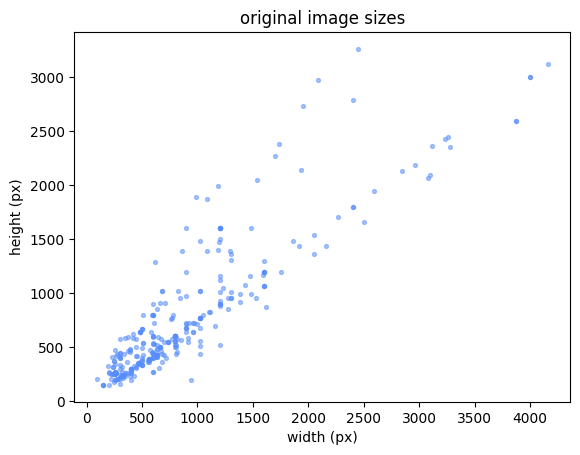

In [6]:
sizes = np.array([Image.open(p).size for p, _ in train_pairs + test_pairs])   # (width, height)
print(f"width  {sizes[:, 0].min()}-{sizes[:, 0].max()} px, height {sizes[:, 1].min()}-{sizes[:, 1].max()} px")
print("most common sizes:", Counter(map(tuple, sizes.tolist())).most_common(3))
# plt.scatter(sizes[:, 0], sizes[:, 1], s=8, alpha=0.5)
# plt.xlabel("width (px)"); plt.ylabel("height (px)"); plt.title("original image sizes");

### 0.3 What do the masks look like?
Each mask is an RGB image. Let's count the colours in a few of them before deciding how to binarize them into 0/1.

# TBD SIWTCH STYLE TO PROF


In [7]:
for _, mp in train_pairs[:3]:
    m = np.array(Image.open(mp).convert("RGB")).reshape(-1, 3)  # SWITCH TO CONVERSION OF PROF
    colours, counts = np.unique(m, axis=0, return_counts=True)
    top = sorted(zip(counts.tolist(), map(tuple, colours.tolist())), reverse=True)[:4]
    print(f"{mp.name:20s} mode={Image.open(mp).mode:4s}  most frequent colours (count, RGB): {top}")

00002.png            mode=P     most frequent colours (count, RGB): [(71246, (0, 0, 0)), (11354, (128, 0, 0))]
00003.png            mode=P     most frequent colours (count, RGB): [(159850, (0, 0, 0)), (110870, (128, 0, 0))]
00004.png            mode=P     most frequent colours (count, RGB): [(2935289, (0, 0, 0)), (175111, (128, 0, 0))]


Disease is drawn in red `(128, 0, 0)` and everything else is black `(0, 0, 0)`. A pixel is therefore
**diseased (1)** if its brightest channel is above a threshold; using a threshold rather than an exact colour
match is robust to compression noise at the edges. Healthy leaf tissue and the photo background are both 0.

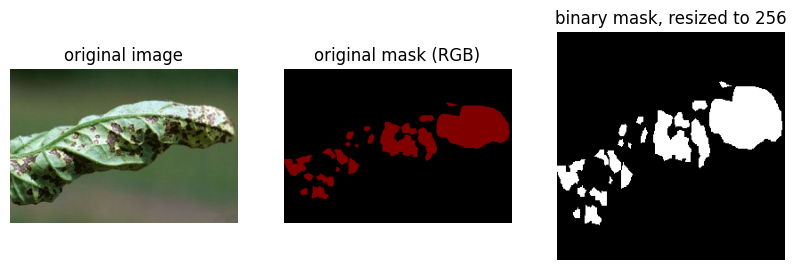

In [8]:
MASK_THRESHOLD = 50

def load_pair(img_path, mask_path, size=IMG_SIZE):
    img = Image.open(img_path).convert("RGB")
    mask = (np.array(Image.open(mask_path).convert("RGB")).max(-1) > MASK_THRESHOLD).astype(np.uint8)
    mask = Image.fromarray(mask)
    if mask.size != img.size:
        mask = mask.resize(img.size, Image.NEAREST)
    # bilinear for the photo, NEAREST for the mask so it stays strictly 0/1
    return (np.array(img.resize((size, size), Image.BILINEAR)),
            np.array(mask.resize((size, size), Image.NEAREST)))

def load_all(pairs):
    imgs, masks = zip(*(load_pair(i, m) for i, m in pairs))
    return np.stack(imgs), np.stack(masks), [i.stem for i, _ in pairs]

i0, m0 = load_pair(*train_pairs[0])
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
ax[0].imshow(Image.open(train_pairs[0][0])); ax[0].set_title("original image")
ax[1].imshow(Image.open(train_pairs[0][1])); ax[1].set_title("original mask (RGB)")
ax[2].imshow(m0, cmap="gray"); ax[2].set_title(f"binary mask, resized to {IMG_SIZE}")
for a in ax: a.axis("off")

### 0.4 Train / validation / test split

- **test** = the official `valid_images`: never used for training or for choosing anything, only for the final numbers;
- **train / val** = a random split of the official `train_images` (val is used to choose hyper-parameters,
  e.g. *k* in kNN, patch size, threshold).

We split by **image**, not by pixel: pixels of the same leaf are highly correlated, so putting pixels of one
image in both train and test would give over-optimistic results.

# TBD  SKEKEARN STYLE

In [9]:
img_pool, m_pool, names_pool = load_all(train_pairs)
img_te, m_te, names_te = load_all(test_pairs)

perm = rng.permutation(len(img_pool))
n_val = int(round(VAL_FRACTION * len(perm)))
va_idx, tr_idx = np.sort(perm[:n_val]), np.sort(perm[n_val:])
img_tr, m_tr = img_pool[tr_idx], m_pool[tr_idx]
img_va, m_va = img_pool[va_idx], m_pool[va_idx]
names_tr = [names_pool[i] for i in tr_idx]; names_va = [names_pool[i] for i in va_idx]
del img_pool, m_pool

pd.DataFrame({split: {"images": len(m), "diseased pixels": f"{m.mean():.1%}",
                      "images without disease": int((m.reshape(len(m), -1).max(1) == 0).sum()),
                      "array MB": round((i.nbytes + m.nbytes) / 1e6)}
              for split, i, m in [("train", img_tr, m_tr), ("val", img_va, m_va), ("test", img_te, m_te)]}).T

,images,diseased pixels,images without disease,array MB
train,423,16.1%,0,111
val,75,15.8%,0,20
test,90,15.7%,0,24


#### Plotting helpers
`overlay` paints the mask in red on the image; `show_examples` makes the image | mask | overlay grid.

# TBD TO SWITCH TOPROF STYLE

In [10]:
POS_NAME = "disease"   # name of class 1, used in plot labels

def overlay(img, mask, color=(255, 0, 0), alpha=0.45):
    out = img.astype(float).copy()
    out[mask > 0] = (1 - alpha) * out[mask > 0] + alpha * np.array(color)
    return out.astype(np.uint8)


def show_examples(images, masks, n=10, idx=None, title=None):
    """n rows: image | mask | overlay."""
    idx = range(n) if idx is None else idx
    fig, axes = plt.subplots(len(idx), 3, figsize=(7.5, 2.5 * len(idx)))
    for row, i in zip(np.atleast_2d(axes), idx):
        row[0].imshow(images[i]); row[1].imshow(masks[i], cmap="gray", vmin=0, vmax=1)
        row[2].imshow(overlay(images[i], masks[i]))
        for a in row:
            a.axis("off")
    for a, t in zip(np.atleast_2d(axes)[0], ["image", f"mask (white = {POS_NAME})", "overlay"]):
        a.set_title(t)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig

### 0.5 Look at the data

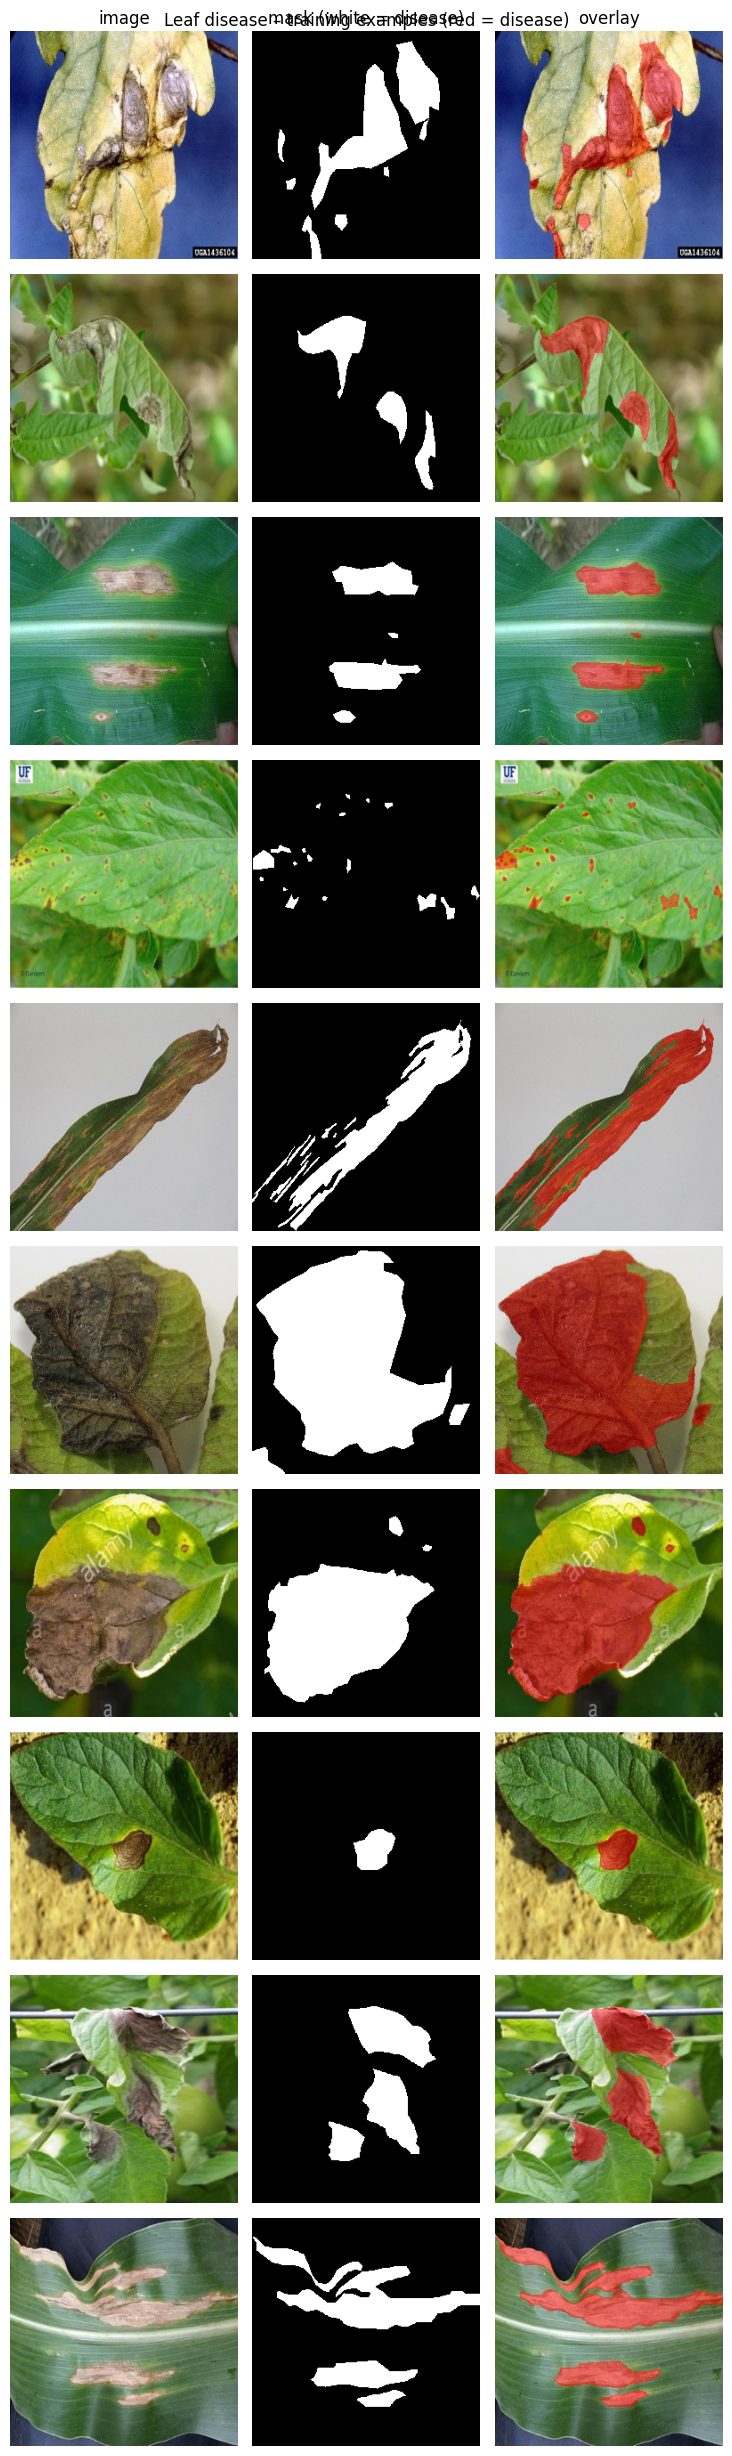

In [11]:
# 10 random training images with their segmentation masks (image | mask | overlay)
show_examples(img_tr, m_tr, idx=rng.choice(len(img_tr), 10, replace=False),
                 title="Leaf disease – training examples (red = disease)");

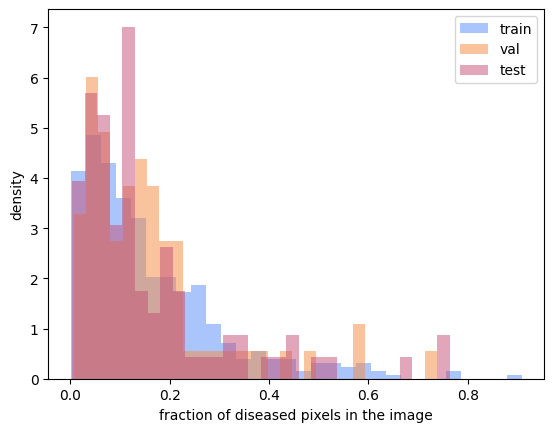

In [12]:
# How much of each image is diseased? Small values = strong class imbalance (accuracy will be misleading)
for split, m in [("train", m_tr), ("val", m_va), ("test", m_te)]:
    plt.hist(m.mean(axis=(1, 2)), bins=30, alpha=0.5, density=True, label=split)
plt.xlabel("fraction of diseased pixels in the image"); plt.ylabel("density"); plt.legend();

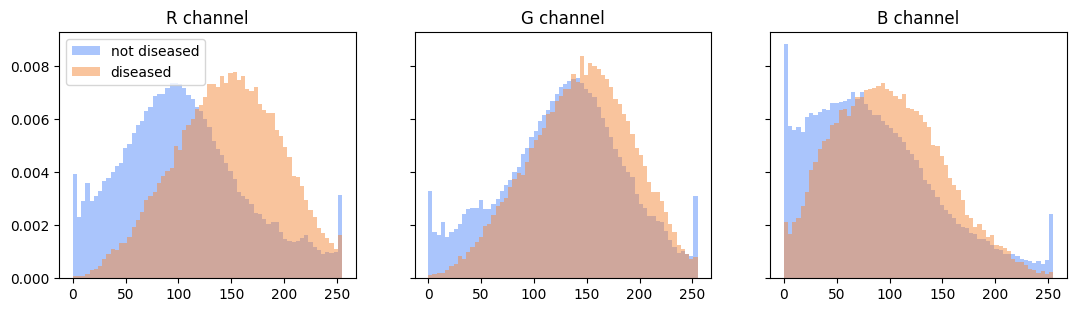

In [13]:
# Colour of diseased vs. healthy/background pixels (preview of what the 1.1 classifier will see)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
pix, lab = img_tr.reshape(-1, 3)[::97], m_tr.ravel()[::97]          # subsample for speed
for c, ax in enumerate(axes):
    for cls, name in [(0, "not diseased"), (1, "diseased")]:
        ax.hist(pix[lab == cls, c], bins=64, range=(0, 255), alpha=0.5, density=True, label=name)
    ax.set_title(f"{'RGB'[c]} channel")
axes[0].legend();

### Evaluation helpers
- `pixel_scores`: per-pixel accuracy, AUC, F1 and confusion matrix on sampled pixels;
- `seg_scores`: IoU / Dice of a whole predicted mask;
- `plot_eval`: ROC curve + confusion matrix;
- `show_predictions`: image | ground truth | probability map | thresholded prediction.

OK BUT D

In [14]:
def pixel_scores(y_true, prob, thr=0.5):
    """Sample-level metrics required by the assignment: accuracy, AUC, confusion matrix."""
    y_pred = (prob >= thr).astype(int)
    return {
        "accuracy": metrics.accuracy_score(y_true, y_pred),
        "AUC": metrics.roc_auc_score(y_true, prob),
        "F1": metrics.f1_score(y_true, y_pred),
        "confusion": metrics.confusion_matrix(y_true, y_pred, labels=[0, 1]),
    }


def seg_scores(mask_true, mask_pred):
    """Segmentation metrics on a whole image: IoU and Dice of the positive class."""
    t, p = mask_true.astype(bool), np.asarray(mask_pred).astype(bool)
    inter, union = (t & p).sum(), (t | p).sum()
    return {"IoU": inter / union if union else 1.0,
            "Dice": 2 * inter / (t.sum() + p.sum()) if (t.sum() + p.sum()) else 1.0,
            "pixel_acc": (t == p).mean()}


def plot_eval(y_true, prob, name, thr=0.5, ax=None):
    """ROC curve + confusion matrix side by side."""
    import seaborn as sns
    s = pixel_scores(y_true, prob, thr)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.6))
    fpr, tpr, _ = metrics.roc_curve(y_true, prob)
    a1.plot(fpr, tpr, label=f"AUC={s['AUC']:.3f}"); a1.plot([0, 1], [0, 1], "k--", lw=0.8)
    a1.set_xlabel("false positive rate"); a1.set_ylabel("true positive rate"); a1.legend(); a1.set_title("ROC")
    sns.heatmap(s["confusion"], annot=True, fmt="d", cmap="Blues", ax=a2,
                xticklabels=["bg", POS_NAME], yticklabels=["bg", POS_NAME])
    a2.set_xlabel("predicted"); a2.set_ylabel("true"); a2.set_title(f"acc={s['accuracy']:.3f}")
    fig.suptitle(name); fig.tight_layout()
    return s


def show_predictions(images, masks, probs, idx, thr=0.5, title=None):
    """rows: image | ground truth | predicted probability | thresholded prediction (+IoU)."""
    fig, axes = plt.subplots(len(idx), 4, figsize=(10, 2.5 * len(idx)))
    for row, i, p in zip(np.atleast_2d(axes), idx, probs):
        iou = seg_scores(masks[i], p >= thr)["IoU"]
        row[0].imshow(images[i]); row[1].imshow(masks[i], cmap="gray", vmin=0, vmax=1)
        row[2].imshow(p, cmap="viridis", vmin=0, vmax=1)
        row[3].imshow(p >= thr, cmap="gray", vmin=0, vmax=1); row[3].set_title(f"prediction, IoU={iou:.2f}", fontsize=9)
        for a in row:
            a.axis("off")
    for a, t in zip(np.atleast_2d(axes)[0], ["image", "ground truth", f"P({POS_NAME})", ""]):
        if t:
            a.set_title(t)
    if title:
        fig.suptitle(title)
    fig.tight_layout()
    return fig

### Bookkeeping
Every experiment is stored in `results` so that at the end we can compare everything in one table.
Besides the per-pixel metrics required by the assignment (accuracy, AUC, confusion matrix) we also compute
**IoU** and **Dice** on full test images, the standard metrics for segmentation.

In [15]:
results = []

def eval_segmentation(segment_fn, n=N_SEG_EVAL, thr=0.5):
    """Mean IoU / Dice of segment_fn(img) -> prob map over the first n test images."""
    scores = [seg_scores(m_te[i], segment_fn(img_te[i]) >= thr) for i in range(min(n, len(img_te)))]
    return {k: np.mean([s[k] for s in scores]) for k in scores[0]}

def record(part, name, y_va, p_va, y_te, p_te, segment_fn=None, train_time=None):
    va, te = pixel_scores(y_va, p_va), pixel_scores(y_te, p_te)
    row = {"part": part, "model": name, "val_AUC": va["AUC"], "test_AUC": te["AUC"],
           "test_acc": te["accuracy"], "test_F1": te["F1"], "train_s": train_time}
    if segment_fn is not None:
        seg = eval_segmentation(segment_fn)
        row.update({"test_mIoU": seg["IoU"], "test_Dice": seg["Dice"]})
    results.append(row)
    return pd.DataFrame([row]).round(3)

## 1.1 Pixel classifier on RGB values

Build the training set by sampling `N_PER_IMG` random pixels from every training image; features are the 3 RGB
values, the label is read from the mask at the same coordinates. Same for val and test.

#### Sampling helpers
A sample is one pixel, identified by `(image index, row y, column x)`. `sample_pixel_coords` picks random pixels, `labels_at` reads their class from the mask, `rgb_at` their colour.
`segment_rgb` applies a trained pixel classifier to every pixel of an image.

In [16]:
def sample_pixel_coords(masks, n_per_image, seed=0, pos_fraction=None):
    """(img_idx, y, x) for n_per_image pixels from each image.

    pos_fraction=None : uniform random pixels (true class distribution, as in the assignment).
    pos_fraction=0.5  : half of the samples drawn from class-1 pixels (when the image has any),
                        useful for TRAINING when the positive class is rare. Always evaluate on
                        uniformly sampled pixels."""
    rng = np.random.default_rng(seed)
    n, h, w = masks.shape
    if pos_fraction is None:
        ii = np.repeat(np.arange(n), n_per_image)
        return ii, rng.integers(0, h, size=ii.size), rng.integers(0, w, size=ii.size)
    ii, ys, xs = [], [], []
    for i in range(n):
        pos = np.flatnonzero(masks[i].ravel())
        k_pos = int(round(pos_fraction * n_per_image)) if pos.size else 0
        flat = np.concatenate([rng.choice(pos, k_pos) if k_pos else np.empty(0, int),
                               rng.integers(0, h * w, size=n_per_image - k_pos)])
        ii.append(np.full(n_per_image, i)); ys.append(flat // w); xs.append(flat % w)
    return np.concatenate(ii), np.concatenate(ys), np.concatenate(xs)


def labels_at(masks, coords):
    ii, ys, xs = coords
    return masks[ii, ys, xs].astype(int)


def rgb_at(images, coords):
    """Exercise 1.1 features: the 3 RGB values of the pixel, scaled to [0, 1]."""
    ii, ys, xs = coords
    return images[ii, ys, xs].astype(np.float32) / 255.0


def _proba(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    # keras model with 1 sigmoid output; large batches are much faster (default would be 32)
    return np.asarray(model.predict(X, batch_size=4096, verbose=0)).reshape(-1)


def segment_rgb(model, img):
    h, w, _ = img.shape
    return _proba(model, img.reshape(-1, 3).astype(np.float32) / 255.0).reshape(h, w)

In [17]:
c_tr = sample_pixel_coords(m_tr, N_PER_IMG, seed=1)
c_va = sample_pixel_coords(m_va, N_PER_IMG, seed=2)
c_te = sample_pixel_coords(m_te, N_PER_IMG, seed=3)
y_tr, y_va, y_te = labels_at(m_tr, c_tr), labels_at(m_va, c_va), labels_at(m_te, c_te)

X_tr, X_va, X_te = rgb_at(img_tr, c_tr), rgb_at(img_va, c_va), rgb_at(img_te, c_te)
print("train samples:", X_tr.shape, " test samples:", X_te.shape)
print(f"fraction of diseased samples: {y_tr.mean():.3f}  ->  "
      f"a classifier that always says 'background' gets accuracy {1 - y_te.mean():.3f} on test")

train samples: (21150, 3)  test samples: (4500, 3)
fraction of diseased samples: 0.159  ->  a classifier that always says 'background' gets accuracy 0.848 on test


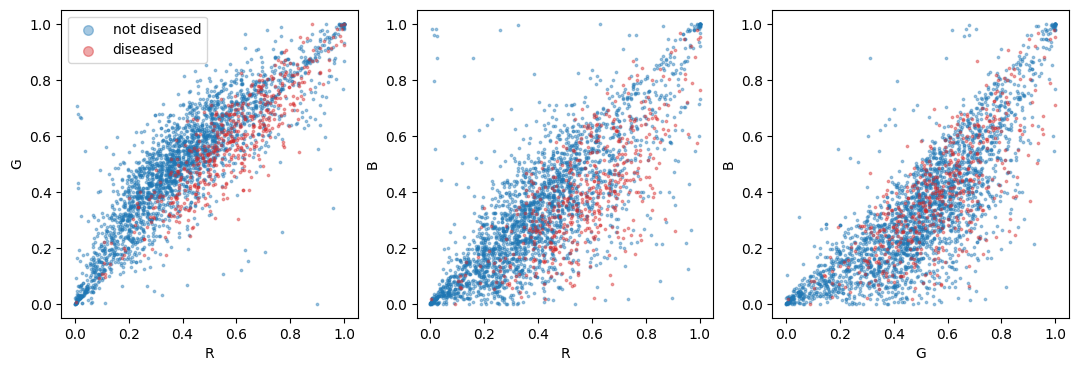

In [18]:
# What does the problem look like in colour space? (a random subset of training samples)
sub = rng.choice(len(X_tr), 3000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    for cls, col in [(0, "tab:blue"), (1, "tab:red")]:
        s = sub[y_tr[sub] == cls]
        ax.scatter(X_tr[s, a], X_tr[s, b], s=3, alpha=0.4, c=col, label=["not diseased", "diseased"][cls])
    ax.set_xlabel("RGB"[a]); ax.set_ylabel("RGB"[b])
axes[0].legend(markerscale=4);

,part,model,val_AUC,test_AUC,test_acc,test_F1,train_s,test_mIoU,test_Dice
0,1.1,LogReg RGB,0.863,0.832,0.846,0.121,0.066,0.09,0.135


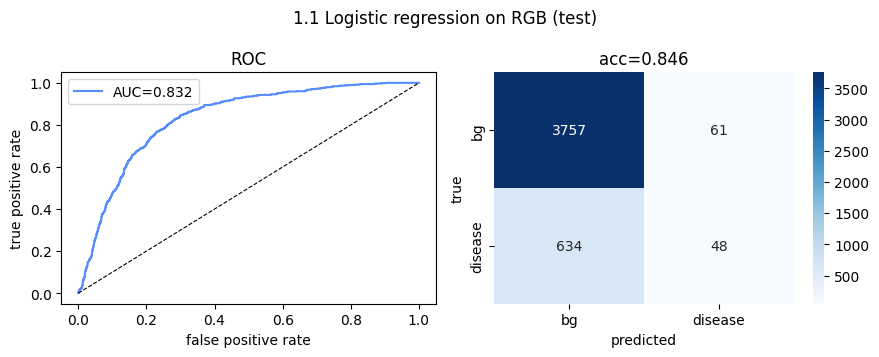

In [19]:
# Logistic regression
t = time.time()
lr_rgb = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
tt = time.time() - t
plot_eval(y_te, lr_rgb.predict_proba(X_te)[:, 1], "1.1 Logistic regression on RGB (test)")
record("1.1", "LogReg RGB", y_va, lr_rgb.predict_proba(X_va)[:, 1], y_te, lr_rgb.predict_proba(X_te)[:, 1],
       lambda im: segment_rgb(lr_rgb, im), tt)

In [20]:
# kNN: choose k on the VALIDATION set, never on test
for k in [1, 5, 25, 75, 151]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    print(f"k={k:4d}  val AUC = {pixel_scores(y_va, knn.predict_proba(X_va)[:, 1])['AUC']:.3f}")

k=   1  val AUC = 0.630
k=   5  val AUC = 0.787
k=  25  val AUC = 0.859
k=  75  val AUC = 0.872
k= 151  val AUC = 0.870


,part,model,val_AUC,test_AUC,test_acc,test_F1,train_s,test_mIoU,test_Dice
0,1.1,kNN75 RGB,0.872,0.847,0.858,0.262,0.028,0.141,0.218


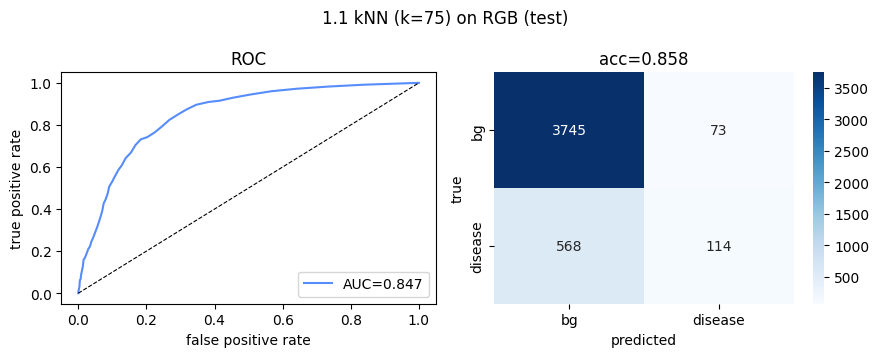

In [21]:
K_BEST = 75   # <- set from the output above
t = time.time()
knn_rgb = KNeighborsClassifier(n_neighbors=K_BEST).fit(X_tr, y_tr)
tt = time.time() - t
plot_eval(y_te, knn_rgb.predict_proba(X_te)[:, 1], f"1.1 kNN (k={K_BEST}) on RGB (test)")
record("1.1", f"kNN{K_BEST} RGB", y_va, knn_rgb.predict_proba(X_va)[:, 1], y_te,
       knn_rgb.predict_proba(X_te)[:, 1], lambda im: segment_rgb(knn_rgb, im), tt)

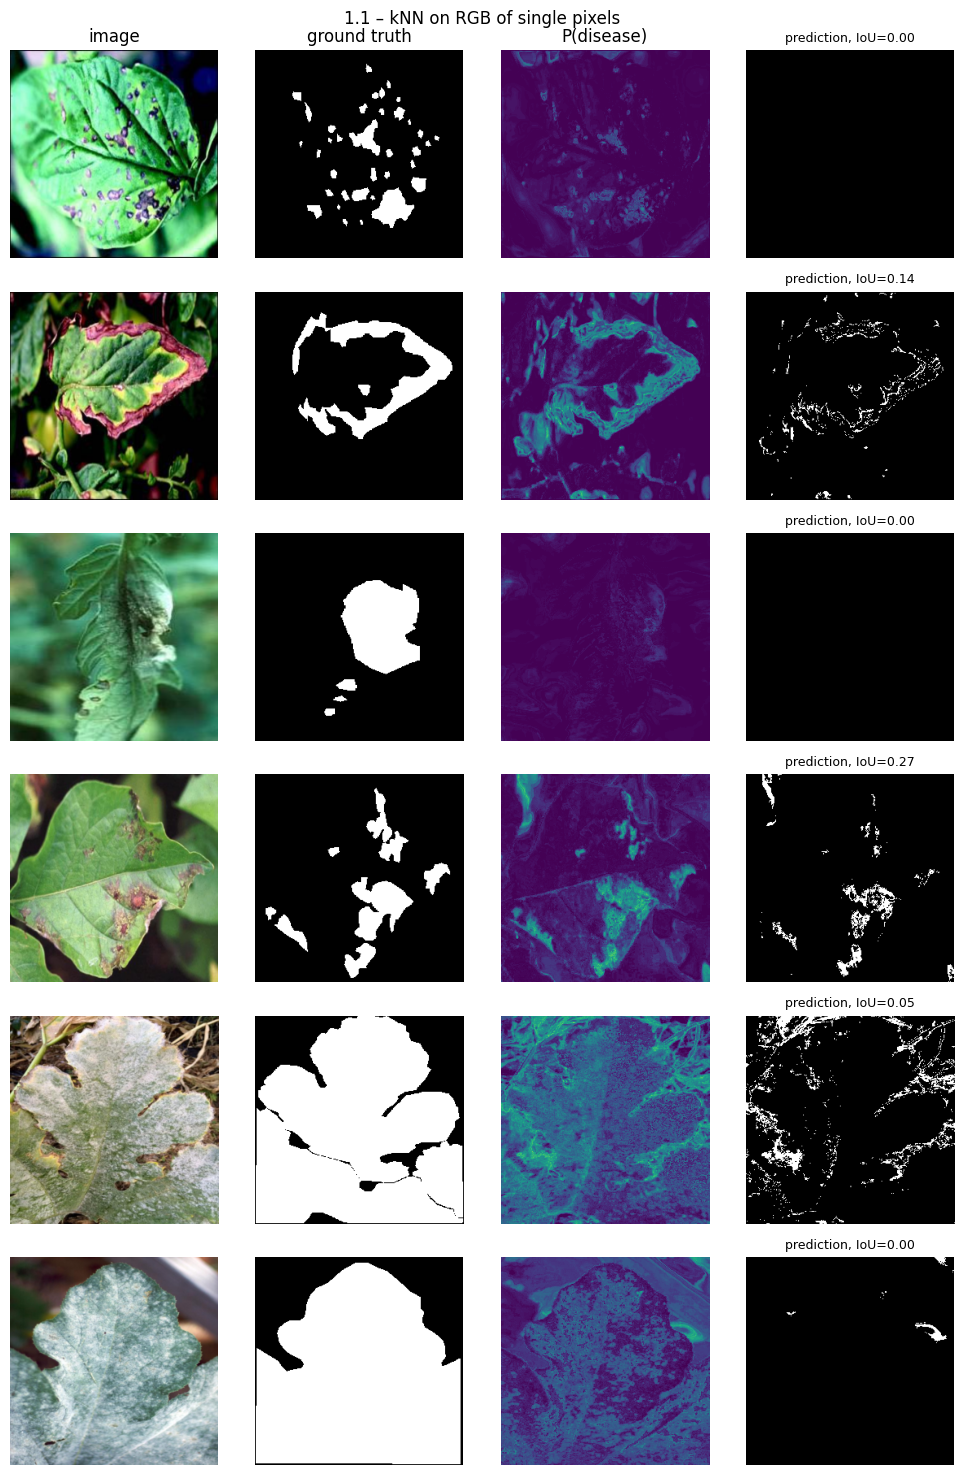

In [22]:
# Apply the classifier to EVERY pixel of some test images -> segmentation
show_idx = list(range(6))
show_predictions(img_te, m_te, [segment_rgb(knn_rgb, img_te[i]) for i in show_idx], show_idx,
                    title="1.1 – kNN on RGB of single pixels");

**Questions for the report (1.1)**
- Is accuracy a good metric here? Compare with the "always background" baseline printed above.
- Which colours does the classifier get wrong? (brown/yellow background, shadows, leaf veins, dried edges…)
- Why does a single pixel's colour fundamentally limit the result? → motivates using a neighbourhood (1.2).

## 1.2 Patch classifiers
Now the classifier sees a `PATCH × PATCH` window centred on the pixel. The label is still the class of the
centre pixel. Images are padded by reflection so border pixels also have a full patch.

### 1.2a Raw patch values (flattened to 15·15·3 = 675 features)

#### Patch helpers
`patches_at` cuts the patch around each sampled pixel (images are padded by reflection so border pixels get a full patch). `image_patches` + `segment_patches` do the same for every pixel of a whole image (with `stride>1` only every n-th pixel is classified and the result is upsampled — much faster).

In [23]:
def patches_at(images, coords, patch=15):
    """Exercise 1.2/1.3: (M, patch, patch, 3) float32 patches centred on each pixel.
    Images are padded by reflection so pixels on the border also get a full patch."""
    r = patch // 2
    padded = np.pad(images, ((0, 0), (r, r), (r, r), (0, 0)), mode="reflect")
    ii, ys, xs = coords
    d = np.arange(patch)
    return padded[ii[:, None, None], ys[:, None, None] + d[None, :, None],
                  xs[:, None, None] + d[None, None, :]].astype(np.float32) / 255.0


def image_patches(img, patch=15, stride=1):
    """All patches of one image as (n_rows, n_cols, patch, patch, 3) float32, using a
    zero-copy sliding-window view (same values as patches_at, ~4x faster)."""
    r = patch // 2
    padded = np.pad(img, ((r, r), (r, r), (0, 0)), mode="reflect")
    v = np.lib.stride_tricks.sliding_window_view(padded, (patch, patch), axis=(0, 1))  # (H, W, 3, p, p)
    v = v[::stride, ::stride].transpose(0, 1, 3, 4, 2)
    return v.astype(np.float32) / 255.0


def segment_patches(model, img, patch=15, flatten=True, stride=1, batch=16384):
    """Classify the patch around every `stride`-th pixel. With stride>1 the
    probability map is upsampled back to full resolution (much faster)."""
    h, w, _ = img.shape
    P = image_patches(img, patch, stride)
    grid = P.shape[:2]
    P = P.reshape(-1, patch, patch, 3)
    probs = []
    for s in range(0, len(P), batch):
        B = P[s:s + batch]
        probs.append(_proba(model, B.reshape(len(B), -1) if flatten else B))
    p = np.concatenate(probs).reshape(grid)
    if stride > 1:
        p = np.array(Image.fromarray(p.astype(np.float32)).resize((w, h), Image.BILINEAR))
    return p

patches: (21150, 15, 15, 3) -> flattened: (21150, 675)


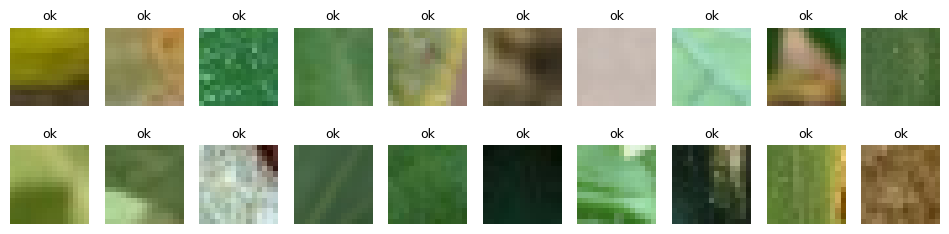

In [24]:
P_tr, P_va, P_te = (patches_at(img_tr, c_tr, PATCH), patches_at(img_va, c_va, PATCH),
                    patches_at(img_te, c_te, PATCH))
Xr_tr, Xr_va, Xr_te = (P.reshape(len(P), -1) for P in (P_tr, P_va, P_te))
print("patches:", P_tr.shape, "-> flattened:", Xr_tr.shape)

# a few training patches with their label
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for ax, j in zip(axes.ravel(), rng.choice(len(P_tr), 20, replace=False)):
    ax.imshow(P_tr[j]); ax.set_title(["ok", "disease"][y_tr[j]], fontsize=9); ax.axis("off")

In [25]:
raw_models = {
    "LogReg raw patch": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1)),
    "RandomForest raw patch": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1,
                                                     random_state=SEED),
}
for name, model in raw_models.items():
    t = time.time(); model.fit(Xr_tr, y_tr); tt = time.time() - t
    display(record("1.2a", name, y_va, model.predict_proba(Xr_va)[:, 1], y_te, model.predict_proba(Xr_te)[:, 1],
                   lambda im, m=model: segment_patches(m, im, PATCH, stride=2), tt))

,part,model,val_AUC,test_AUC,test_acc,test_F1,train_s,test_mIoU,test_Dice
0,1.2a,LogReg raw patch,0.838,0.811,0.848,0.218,4.744,0.153,0.233


,part,model,val_AUC,test_AUC,test_acc,test_F1,train_s,test_mIoU,test_Dice
0,1.2a,RandomForest raw patch,0.884,0.863,0.856,0.22,15.059,0.144,0.219


### 1.2b Hand-crafted patch features
For each pixel: its RGB, the **mean** and **standard deviation** of R, G, B in the patch, the mean and std of the
**gradient magnitude** (texture / edges) in the patch, the pixel's **saturation** and the mean saturation in the
patch → 13 features. They are computed as filter responses (box filter, Sobel), the same tools as in the
filtering lab, so a whole image is processed in milliseconds.

#### Feature helpers

In [26]:
FEATURE_NAMES = (["R", "G", "B"] + [f"mean_{c}" for c in "RGB"] + [f"std_{c}" for c in "RGB"]
                 + ["grad_mag_mean", "grad_mag_std", "sat", "mean_sat"])


def feature_map(img, patch=15, use_position=False):
    """Per-pixel feature stack (H, W, F) describing the patch around each pixel:
    pixel RGB, mean & std of RGB in the patch, mean & std of the gradient magnitude,
    pixel saturation, mean saturation. Optionally the normalized (y, x) position."""
    xp, xndi = np, ndi
    x = xp.asarray(img, dtype=xp.float32) / 255.0
    box = lambda a: xndi.uniform_filter(a, size=patch, mode="reflect")  # noqa: E731
    mean = xp.stack([box(x[..., c]) for c in range(3)], -1)
    sq = xp.stack([box(x[..., c] ** 2) for c in range(3)], -1)
    std = xp.sqrt(xp.clip(sq - mean ** 2, 0, None))
    gray = x.mean(-1)
    gmag = xp.hypot(xndi.sobel(gray, 0), xndi.sobel(gray, 1))
    gmean = box(gmag)
    gstd = xp.sqrt(xp.clip(box(gmag ** 2) - gmean ** 2, 0, None))
    sat = x.max(-1) - x.min(-1)
    feats = [x, mean, std, gmean[..., None], gstd[..., None], sat[..., None], box(sat)[..., None]]
    if use_position:
        h, w = gray.shape
        yy, xx = xp.mgrid[0:h, 0:w]
        feats += [(yy / h)[..., None].astype(xp.float32), (xx / w)[..., None].astype(xp.float32)]
    out = xp.concatenate(feats, -1)
    return out


def features_at(images, coords, patch=15, use_position=False):
    """Hand-crafted features for the sampled pixels (computes one feature map per image)."""
    ii, ys, xs = coords
    out = None
    for i in np.unique(ii):
        sel = ii == i
        fm = feature_map(images[i], patch, use_position)
        if out is None:
            out = np.zeros((ii.size, fm.shape[-1]), np.float32)
        out[sel] = fm[ys[sel], xs[sel]]
    return out


def segment_features(model, img, patch=15, use_position=False):
    fm = feature_map(img, patch, use_position)
    h, w, f = fm.shape
    return _proba(model, fm.reshape(-1, f)).reshape(h, w)

In [27]:
F_tr, F_va, F_te = (features_at(img_tr, c_tr, PATCH), features_at(img_va, c_va, PATCH),
                    features_at(img_te, c_te, PATCH))
print(F_tr.shape, FEATURE_NAMES)

(21150, 13) ['R', 'G', 'B', 'mean_R', 'mean_G', 'mean_B', 'std_R', 'std_G', 'std_B', 'grad_mag_mean', 'grad_mag_std', 'sat', 'mean_sat']


In [28]:
feat_models = {
    "LogReg features": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "RandomForest features": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1,
                                                    random_state=SEED),
    "MLP (sklearn) features": make_pipeline(StandardScaler(),
                                            MLPClassifier((64, 32), max_iter=300, early_stopping=True,
                                                          random_state=SEED)),
}
for name, model in feat_models.items():
    t = time.time(); model.fit(F_tr, y_tr); tt = time.time() - t
    display(record("1.2b", name, y_va, model.predict_proba(F_va)[:, 1], y_te, model.predict_proba(F_te)[:, 1],
                   lambda im, m=model: segment_features(m, im, PATCH), tt))

,part,model,val_AUC,test_AUC,test_acc,test_F1,train_s,test_mIoU,test_Dice
0,1.2b,LogReg features,0.882,0.843,0.849,0.311,0.322,0.238,0.345


,part,model,val_AUC,test_AUC,test_acc,test_F1,train_s,test_mIoU,test_Dice
0,1.2b,RandomForest features,0.906,0.889,0.871,0.434,4.162,0.244,0.344


,part,model,val_AUC,test_AUC,test_acc,test_F1,train_s,test_mIoU,test_Dice
0,1.2b,MLP (sklearn) features,0.923,0.898,0.877,0.558,9.021,0.369,0.493


In [29]:
# SVM with RBF kernel scales badly with the number of samples -> train on a subset
n_svm = min(5000, len(F_tr))
svm = make_pipeline(StandardScaler(), SVC(C=1.0, gamma="scale", probability=True, random_state=SEED))
t = time.time(); svm.fit(F_tr[:n_svm], y_tr[:n_svm]); tt = time.time() - t
record("1.2b", f"SVM-RBF features ({n_svm} samples)", y_va, svm.predict_proba(F_va)[:, 1], y_te,
       svm.predict_proba(F_te)[:, 1], None, tt)

,part,model,val_AUC,test_AUC,test_acc,test_F1,train_s
0,1.2b,SVM-RBF features (5000 samples),0.853,0.841,0.861,0.458,4.064


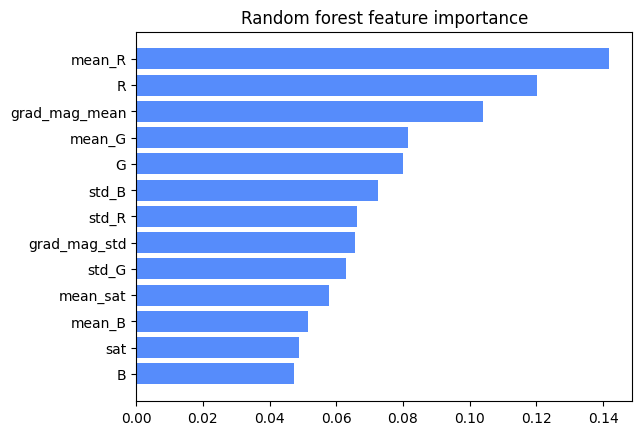

In [30]:
# Which features matter? (random forest impurity importance)
rf_feat = feat_models["RandomForest features"]
order = np.argsort(rf_feat.feature_importances_)
plt.barh(np.array(FEATURE_NAMES)[order], rf_feat.feature_importances_[order])
plt.title("Random forest feature importance");

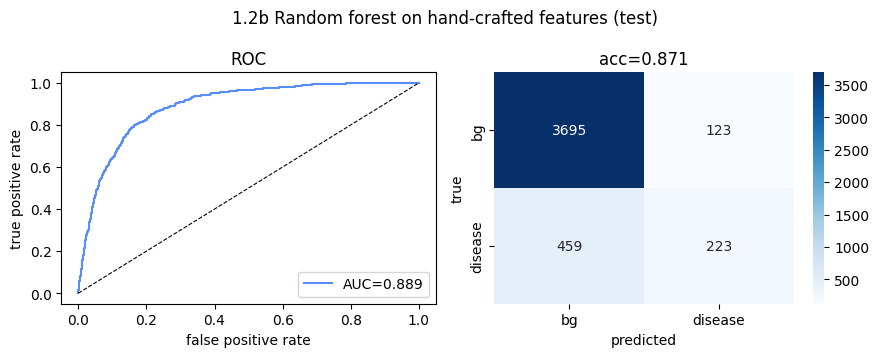

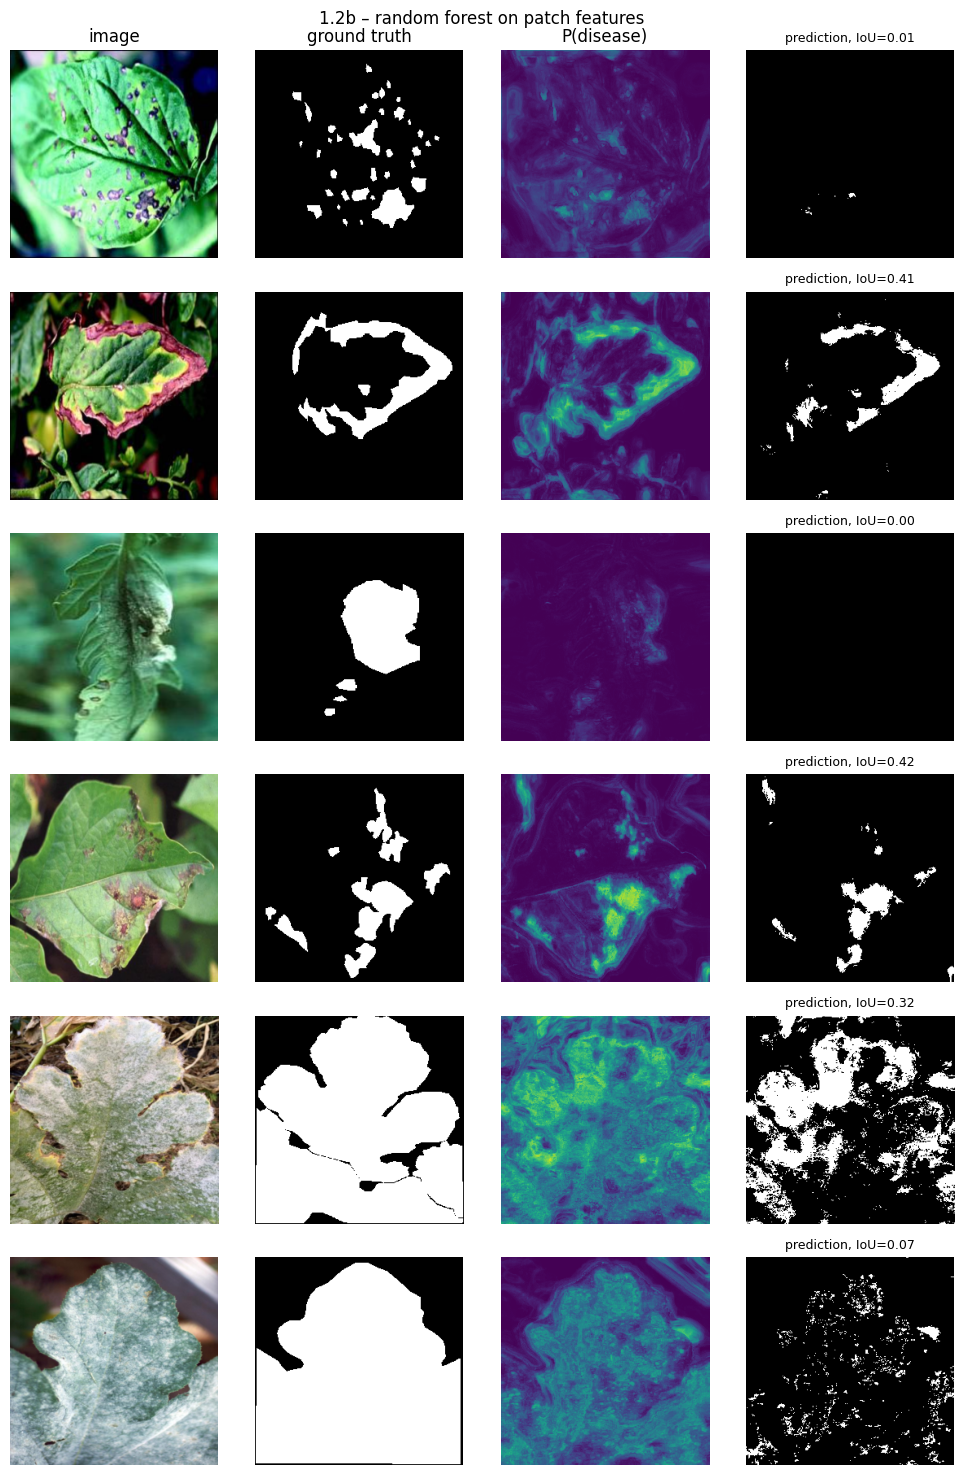

In [31]:
plot_eval(y_te, rf_feat.predict_proba(F_te)[:, 1], "1.2b Random forest on hand-crafted features (test)")
show_predictions(img_te, m_te, [segment_features(rf_feat, img_te[i], PATCH) for i in show_idx], show_idx,
                    title="1.2b – random forest on patch features");

### 1.2 extensions (pick some for the report)
**(i) Patch size.** Larger windows see more context but blur the boundaries. Choose on the validation set.

In [32]:
for p in [5, 9, 15, 25, 41]:
    Fa, Fb = features_at(img_tr, c_tr, p), features_at(img_va, c_va, p)
    m = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED).fit(Fa, y_tr)
    print(f"patch {p:2d}: val AUC = {pixel_scores(y_va, m.predict_proba(Fb)[:, 1])['AUC']:.3f}")

patch  5: val AUC = 0.896
patch  9: val AUC = 0.899
patch 15: val AUC = 0.903
patch 25: val AUC = 0.907
patch 41: val AUC = 0.902


**(ii) Class imbalance.** Diseased pixels are a minority, so uniformly sampled training sets contain few
positives. Two remedies: draw half of the *training* pixels from diseased regions (`pos_fraction=0.5`), and/or
choose the decision threshold on the validation set instead of using 0.5. Val/test stay uniformly sampled so
the metrics still reflect the true distribution.

In [33]:
c_trb = sample_pixel_coords(m_tr, N_PER_IMG, seed=4, pos_fraction=0.5)
y_trb, F_trb = labels_at(m_tr, c_trb), features_at(img_tr, c_trb, PATCH)
print(f"balanced training set: {y_trb.mean():.1%} diseased (uniform sampling gave {y_tr.mean():.1%})")
rf_bal = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
t = time.time(); rf_bal.fit(F_trb, y_trb); tt = time.time() - t
record("1.2b", "RandomForest features, balanced sampling", y_va, rf_bal.predict_proba(F_va)[:, 1], y_te,
       rf_bal.predict_proba(F_te)[:, 1], lambda im: segment_features(rf_bal, im, PATCH), tt)

balanced training set: 58.1% diseased (uniform sampling gave 15.9%)


,part,model,val_AUC,test_AUC,test_acc,test_F1,train_s,test_mIoU,test_Dice
0,1.2b,"RandomForest features, balanced sampling",0.911,0.888,0.76,0.525,1.854,0.374,0.508


best threshold 0.25:  test F1 0.591  (vs 0.434 at 0.5)
test mIoU at best threshold: 0.41


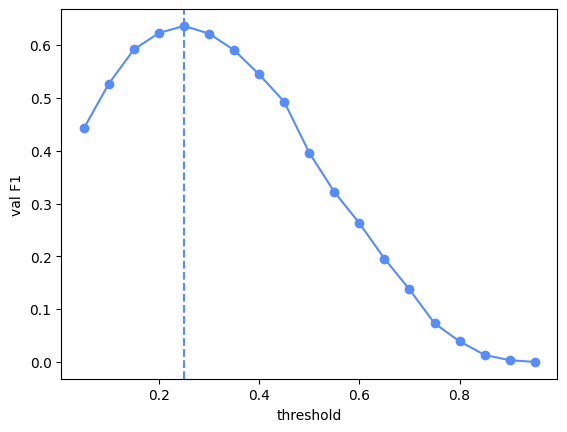

In [34]:
# Threshold chosen on VALIDATION to maximise F1 (then reported on test)
from sklearn.metrics import f1_score
p_va = rf_feat.predict_proba(F_va)[:, 1]
thrs = np.linspace(0.05, 0.95, 19)
f1s = [f1_score(y_va, p_va >= t) for t in thrs]
best_thr = thrs[int(np.argmax(f1s))]
plt.plot(thrs, f1s, marker="o"); plt.xlabel("threshold"); plt.ylabel("val F1"); plt.axvline(best_thr, ls="--")
p_te_rf = rf_feat.predict_proba(F_te)[:, 1]
print(f"best threshold {best_thr:.2f}:  test F1 {f1_score(y_te, p_te_rf >= best_thr):.3f}  "
      f"(vs {f1_score(y_te, p_te_rf >= 0.5):.3f} at 0.5)")
print("test mIoU at best threshold:",
      round(eval_segmentation(lambda im: segment_features(rf_feat, im, PATCH), thr=best_thr)["IoU"], 3))

**(iii) Post-processing.** Pixel classifiers make isolated, noisy decisions. Smoothing the probability map
(Gaussian filter) and removing small blobs (morphological opening) often improves IoU.
Careful: lesions can be tiny, so a too-large opening also deletes true detections — try a few sizes.

In [35]:
def smooth_seg(prob, sigma=3, open_size=5):
    p = ndi.gaussian_filter(prob, sigma)
    return ndi.binary_opening(p >= 0.5, structure=np.ones((open_size, open_size))).astype(float)

before = eval_segmentation(lambda im: segment_features(rf_feat, im, PATCH))
after = eval_segmentation(lambda im: smooth_seg(segment_features(rf_feat, im, PATCH)))
print(f"RF features   mIoU: {before['IoU']:.3f}  ->  with smoothing + opening: {after['IoU']:.3f}")

RF features   mIoU: 0.244  ->  with smoothing + opening: 0.221


## 1.3 Neural networks on patches (Keras)
- **MLP**: input = flattened patch (675 values), like the feed-forward net of the image-classification lab.
- **CNN**: input = the patch as a 15×15×3 array; convolutions exploit the spatial structure.

Neural networks like more data, so we sample more pixels per image here.

In [40]:
import keras
from keras import layers

BATCH = 256     # training batch size

N_PER_IMG_NN = 150
cn_tr = sample_pixel_coords(m_tr, N_PER_IMG_NN, seed=11)
cn_va = sample_pixel_coords(m_va, N_PER_IMG_NN, seed=12)
yn_tr, yn_va = labels_at(m_tr, cn_tr), labels_at(m_va, cn_va)
Pn_tr, Pn_va = patches_at(img_tr, cn_tr, PATCH), patches_at(img_va, cn_va, PATCH)
print("NN training patches:", Pn_tr.shape)

def train(model, X, y, Xv, yv, epochs=30):
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=4, restore_best_weights=True)
    t = time.time()
    h = model.fit(X, y, validation_data=(Xv, yv), epochs=epochs, batch_size=BATCH, callbacks=[stop], verbose=2)
    tt = time.time() - t
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3))
    a1.plot(h.history["loss"], label="train"); a1.plot(h.history["val_loss"], label="val"); a1.set_title("loss")
    a2.plot(h.history["auc"], label="train"); a2.plot(h.history["val_auc"], label="val"); a2.set_title("AUC")
    a1.legend(); a1.set_xlabel("epoch"); a2.set_xlabel("epoch")
    return tt

ModuleNotFoundError: No module named 'tensorflow'

In [ ]:
mlp = keras.Sequential([
    keras.Input(shape=(PATCH * PATCH * 3,)),
    layers.Dense(256, activation="relu"), layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
mlp.summary()
tt = train(mlp, Pn_tr.reshape(len(Pn_tr), -1), yn_tr, Pn_va.reshape(len(Pn_va), -1), yn_va)
p_te = mlp.predict(Xr_te, verbose=0).ravel()
plot_eval(y_te, p_te, "1.3 Keras MLP on flattened patch (test)")
record("1.3", "Keras MLP raw patch", y_va, mlp.predict(Xr_va, verbose=0).ravel(), y_te, p_te,
       lambda im: segment_patches(mlp, im, PATCH, flatten=True, stride=2), tt)

In [ ]:
cnn = keras.Sequential([
    keras.Input(shape=(PATCH, PATCH, 3)),
    layers.RandomFlip("horizontal_and_vertical"),        # augmentation: leaves have no "up", flips keep the label
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),                               # 15 -> 7
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),                               # 7 -> 3
    layers.Flatten(),
    layers.Dense(64, activation="relu"), layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])
cnn.summary()
tt = train(cnn, Pn_tr, yn_tr, Pn_va, yn_va)
p_te = cnn.predict(P_te, verbose=0).ravel()
plot_eval(y_te, p_te, "1.3 Keras CNN on 15x15x3 patch (test)")
record("1.3", "Keras CNN patch", y_va, cnn.predict(P_va, verbose=0).ravel(), y_te, p_te,
       lambda im: segment_patches(cnn, im, PATCH, flatten=False, stride=2), tt)

In [ ]:
show_predictions(img_te, m_te, [segment_patches(cnn, img_te[i], PATCH, flatten=False, stride=2)
                                   for i in show_idx], show_idx, title="1.3 – CNN patch classifier");

## Summary of all experiments

In [ ]:
summary = pd.DataFrame(results).sort_values("test_AUC", ascending=False).round(3)
summary

In [ ]:
fig, ax = plt.subplots(figsize=(8, 0.45 * len(summary) + 1))
s = summary.sort_values("test_AUC")
ax.barh(s["part"] + "  " + s["model"], s["test_AUC"])
ax.set_xlim(0.5, 1); ax.set_xlabel("test AUC (per pixel)"); ax.set_title("Part 1 – model comparison");

**Things to discuss in the report**
- Gain from 1.1 → 1.2 → 1.3: how much does *context* help compared to a better *classifier*?
- Per-pixel AUC vs. image-level IoU: can a model have good AUC but poor IoU? Why?
- Speed: segmenting one 256×256 image means 65 536 classifications. Which models are practical?
- Failure cases: tiny lesions, brown backgrounds or soil, shadows, leaf edges, and annotation ambiguity
  (where exactly does a lesion end?). Show a few examples where the model fails.
- Teaser for Part 2: the CNN above classifies each patch independently and recomputes the same convolutions
  for overlapping patches. A **fully convolutional network** does all pixels at once — and a **U-Net** adds
  much larger context.